In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/recipe-for-rating-predict-food-ratings-using-ml/sample.csv
/kaggle/input/recipe-for-rating-predict-food-ratings-using-ml/train.csv
/kaggle/input/recipe-for-rating-predict-food-ratings-using-ml/test.csv


<center>
    <div style="display: flex; align-items: center; justify-content: center;">
        <div style="flex: 1;">
            <img src="https://podgoodies.iitmadrasonline.in/cdn/shop/files/pod_logo_1.png?v=1628763162" alt="Image" width="400" style="margin-top: 20px;"/>
        </div>
        <div style="flex: 1; text-align: left; padding-left: 20px;">
            <font size="3"></font><br>
            <font size="6"><b>MLP Project (Jan 2024)</b></font><br>
            <font size="4"><u>Recipe for Rating: Predict Food Ratings using ML</u></font><br>
            <font size="2"><b>Submitted by -</b></font><br>
            Name -Ritik Ranjan<br>
            Roll Number - [roll no. removed]<br>
            Kaggle Username - ritik9929<br>
            Email-id - [email removed]
        </div>
    </div>
</center>

# Importing Dependencies

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import pandas as pd
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import chi2
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

from sklearn.naive_bayes import MultinomialNB
from sklearn.feature_selection import SelectPercentile
from sklearn.svm import LinearSVC
from sklearn.decomposition import PCA
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn import svm
from scipy.stats import chi2_contingency
from sklearn.pipeline import make_pipeline
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import GradientBoostingClassifier 
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import SGDClassifier
from sklearn.ensemble import StackingClassifier
from sklearn.preprocessing import MinMaxScaler
from textblob.sentiments import NaiveBayesAnalyzer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.metrics import f1_score,accuracy_score
from sklearn.metrics import classification_report
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.neural_network import MLPClassifier

from sklearn.ensemble import VotingClassifier
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

In [3]:
# Kernel Runtime Management
import os
import sys
import warnings
if not sys.warnoptions:
    # To ignore warinings
    warnings.simplefilter("ignore")
    os.environ["PYTHONWARNINGS"] = "ignore"

# Data Processing
import pandas as pd
from scipy.sparse import hstack

# Linear Algebra
import numpy as np

# ML/DL Libraries
import sklearn as sk
import xgboost as xgb
import lightgbm as lgb
from sklearn import (naive_bayes,tree,ensemble,neighbors,semi_supervised,discriminant_analysis,svm,linear_model,neural_network,gaussian_process)
from sklearn.dummy import DummyClassifier 

# Performance Evaluation Metrics
from sklearn.metrics import accuracy_score, f1_score
from sklearn.metrics import classification_report
from sklearn.model_selection import cross_val_score

# Visualization Libraries
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import set_config, compose, pipeline
set_config(display='diagram')
%matplotlib inline

# Pre-processing/Feature Engineering 
import regex
from sklearn.feature_selection import chi2, mutual_info_regression, SelectKBest
from sklearn.model_selection import GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.feature_extraction.text import CountVectorizer, TfidfTransformer, TfidfVectorizer
from sklearn.preprocessing import (StandardScaler, OneHotEncoder, StandardScaler, FunctionTransformer,
                                   PolynomialFeatures, QuantileTransformer, PowerTransformer, RobustScaler)

# Cross Validation
from sklearn.utils import class_weight
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.feature_selection import VarianceThreshold

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

# Loading Dataset

In [5]:
df_train = pd.read_csv("/kaggle/input/recipe-for-rating-predict-food-ratings-using-ml/train.csv")
df_test = pd.read_csv("/kaggle/input/recipe-for-rating-predict-food-ratings-using-ml/test.csv")
df_train1 = pd.read_csv("/kaggle/input/recipe-for-rating-predict-food-ratings-using-ml/train.csv")
df_sample = pd.read_csv("/kaggle/input/recipe-for-rating-predict-food-ratings-using-ml/sample.csv")

In [6]:
print("Duplicates in train dataset:", df_train.duplicated().sum())
print("Duplicates in test datset:", df_test.duplicated().sum())

Duplicates in train dataset: 0
Duplicates in test datset: 0


In [7]:
import string

def preprocess_text(text):
    text = ''.join([char if char not in string.punctuation else ' ' for char in text])
    text = ' '.join(text.split())
    return text

df_train['Recipe_Review'] = df_train['Recipe_Review'].astype(str)
df_test['Recipe_Review'] = df_test['Recipe_Review'].astype(str)

df_train['Recipe_Review'] = df_train['Recipe_Review'].apply(preprocess_text)
df_test['Recipe_Review'] = df_test['Recipe_Review'].apply(preprocess_text)

In [8]:
df_train['Recipe_Review'] = df_train['Recipe_Review'].str.lower()
df_test['Recipe_Review'] = df_test['Recipe_Review'].str.lower()

In [9]:
df_train.shape

(13636, 15)

In [10]:
df_test.shape

(4546, 14)

In [11]:
df_test.head()

,ID,RecipeNumber,RecipeCode,RecipeName,CommentID,UserID,UserName,UserReputation,CreationTimestamp,ReplyCount,ThumbsUpCount,ThumbsDownCount,BestScore,Recipe_Review
0,86,45,41384,Black Bean ‘n’ Pumpkin Chili,sp_aUSaElGf_41384_c_341929,u_1oKc4U6bh65cEli8Z8eTIf98Vpr,kalloween,1,1622718043,0,0,0,100,this was so good the pumpkin was perfect as a ...
1,102,53,3143,Pumpkin Bars,sp_aUSaElGf_3143_c_274545,u_1oKW5seFLQMSwAeOfBVmwJizy5D,chocolate desert,1,1622717685,0,0,1,100,so good could not stop eating them so bad good...
2,156,53,3143,Pumpkin Bars,sp_aUSaElGf_3143_c_398512,u_1oKZ6GUIAIol8xe6oEI7t1Mpxdz,Vantreesta,1,1622718307,0,0,0,100,i use a small ladle to fill muffin cups
3,18,89,1324,Porcupine Meatballs,sp_aUSaElGf_1324_c_431662,u_1oKWCP33NVk4Osfpu4VJuIckEF0,Roberta L.Beauchamp,1,1622648872,0,4,3,212,i made this and followed the instructions as d...
4,27,70,32264,Easy Chicken Enchiladas,sp_aUSaElGf_32264_c_423935,u_1oKVhIJMuUlrSCVkbO1jheVTol8,fhquilting,1,1622718460,0,0,1,100,very good i used corn tortillas used fresh cho...


In [12]:
df_sample

,ID,Rating
0,1,5
1,2,2
2,3,4
3,4,2
4,5,4
...,...,...
995,996,3
996,997,0
997,998,1
998,999,0


In [13]:
df_train.describe()

,ID,RecipeNumber,RecipeCode,UserReputation,CreationTimestamp,ReplyCount,ThumbsUpCount,ThumbsDownCount,Rating,BestScore
count,13636.000000,13636.000000,13636.000000,13636.000000,1.363600e+04,13636.000000,13636.000000,13636.000000,13636.000000,13636.000000
mean,121.085289,38.624377,21785.990833,2.160311,1.623713e+09,0.014520,1.098269,0.543708,4.288721,153.127897
std,116.995633,29.672351,23883.189918,10.086424,5.444020e+06,0.137323,4.166487,3.265660,1.544839,140.986908
min,0.000000,1.000000,386.000000,0.000000,1.613035e+09,0.000000,0.000000,0.000000,0.000000,0.000000
25%,45.000000,12.000000,6504.000000,1.000000,1.622717e+09,0.000000,0.000000,0.000000,5.000000,100.000000
50%,91.000000,33.000000,14600.000000,1.000000,1.622718e+09,0.000000,0.000000,0.000000,5.000000,100.000000
75%,148.000000,63.000000,33121.000000,1.000000,1.622718e+09,0.000000,0.000000,0.000000,5.000000,100.000000
max,724.000000,100.000000,191775.000000,510.000000,1.665756e+09,3.000000,80.000000,126.000000,5.000000,946.000000


In [14]:
df_test.describe()

,ID,RecipeNumber,RecipeCode,UserReputation,CreationTimestamp,ReplyCount,ThumbsUpCount,ThumbsDownCount,BestScore
count,4546.000000,4546.000000,4546.000000,4546.000000,4.546000e+03,4546.000000,4546.000000,4546.000000,4546.000000
mean,122.605147,38.884294,21736.701936,2.157501,1.623702e+09,0.014958,1.062253,0.566212,153.264848
std,116.006955,30.129333,24211.777711,9.797366,5.542652e+06,0.139922,4.303231,4.021903,141.355650
min,0.000000,1.000000,386.000000,0.000000,1.613035e+09,0.000000,0.000000,0.000000,12.000000
25%,46.000000,11.000000,6086.000000,1.000000,1.622717e+09,0.000000,0.000000,0.000000,100.000000
50%,92.000000,32.000000,14600.000000,1.000000,1.622718e+09,0.000000,0.000000,0.000000,100.000000
75%,154.000000,64.000000,33121.000000,1.000000,1.622718e+09,0.000000,0.000000,0.000000,100.000000
max,715.000000,100.000000,191775.000000,520.000000,1.665669e+09,3.000000,106.000000,122.000000,931.000000


In [15]:
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13636 entries, 0 to 13635
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   ID                 13636 non-null  int64 
 1   RecipeNumber       13636 non-null  int64 
 2   RecipeCode         13636 non-null  int64 
 3   RecipeName         13636 non-null  object
 4   CommentID          13636 non-null  object
 5   UserID             13636 non-null  object
 6   UserName           13636 non-null  object
 7   UserReputation     13636 non-null  int64 
 8   CreationTimestamp  13636 non-null  int64 
 9   ReplyCount         13636 non-null  int64 
 10  ThumbsUpCount      13636 non-null  int64 
 11  ThumbsDownCount    13636 non-null  int64 
 12  Rating             13636 non-null  int64 
 13  BestScore          13636 non-null  int64 
 14  Recipe_Review      13636 non-null  object
dtypes: int64(10), object(5)
memory usage: 1.6+ MB


In [16]:
df_train.isnull().sum()

ID                   0
RecipeNumber         0
RecipeCode           0
RecipeName           0
CommentID            0
UserID               0
UserName             0
UserReputation       0
CreationTimestamp    0
ReplyCount           0
ThumbsUpCount        0
ThumbsDownCount      0
Rating               0
BestScore            0
Recipe_Review        0
dtype: int64

In [17]:
df_train

,ID,RecipeNumber,RecipeCode,RecipeName,CommentID,UserID,UserName,UserReputation,CreationTimestamp,ReplyCount,ThumbsUpCount,ThumbsDownCount,Rating,BestScore,Recipe_Review
0,70,71,12259,Banana Bars with Cream Cheese Frosting,sp_aUSaElGf_12259_c_149978,u_1oKVaBmiEKwAFyiHrDLoWpbel0J,misscoffeepot,20,1622717078,0,0,0,5,100,great recipe i have made them just as written ...
1,72,88,8202,Simple Taco Soup,sp_aUSaElGf_8202_c_310332,u_1oKZeRIXYzGNhGW8OMR3O4lX1ih,MichelleMalone,1,1622717852,0,0,1,5,100,this is an easy and quick recipe that is great...
2,458,3,2832,Cheeseburger Soup,sp_aUSaElGf_2832_c_206522,u_1oKYHUtdaD48KJCDYq5wfpAUxWz,jeannem32,1,1622717357,0,0,0,3,100,i think i was looking for something extra spec...
3,7,50,100276,Grilled Huli Huli Chicken,sp_aUSaElGf_100276_c_434088,u_1oKZCQcKQZdQhDVBS7oISc216VA,ds422,1,1622648899,0,0,0,5,100,this is our favorite grilled chicken recipe gr...
4,60,12,19731,Cauliflower Soup,sp_aUSaElGf_19731_c_387011,u_1oKd4sudZQPgu6YALiC7bW7mKMs,SusanHoward,1,1622718260,0,0,0,4,100,great basic recipe i added 2 teaspoons tuscan ...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13631,115,98,11767,Quick Cream of Mushroom Soup,sp_aUSaElGf_11767_c_127710,u_1oKVbHjirkAIWwTjbt9dWyqENo2,elbay,1,1622716969,0,0,0,5,100,delicious very easy to make one minor change i...
13632,372,6,21444,Favorite Chicken Potpie,sp_aUSaElGf_21444_c_196030,u_1oKXoBnyJ2ocquNYwAhs19LMSrA,PauletteInhofe,1,1622717329,0,0,0,5,100,i made this pie for my family and they loved i...
13633,87,37,20170,Taco Lasagna,sp_aUSaElGf_20170_c_359338,u_1oKbGr5o9tj0mQl1rkVqzWnE481,Barbaralarkin,1,1622718089,0,0,0,5,100,very tasty
13634,48,63,24886,Chicken and Dumplings,sp_aUSaElGf_24886_c_175514,u_1oKWD7Dqjmc0oYHdW8Vm3fzhxJW,SammyPrissy,1,1622717192,0,0,0,5,100,i have made this numerous times it 39 s so goo...


In [18]:
df_train['Rating'].value_counts()

Rating
5    10371
0     1272
4     1241
3      368
1      210
2      174
Name: count, dtype: int64

In [19]:
df_train['UserReputation'].value_counts()

UserReputation
1      12708
10       478
20       217
0        118
30        54
50        16
40        12
90         7
80         4
60         4
110        3
510        3
100        3
140        2
70         2
220        1
160        1
130        1
150        1
300        1
Name: count, dtype: int64

In [20]:
df_train['BestScore'].value_counts()

BestScore
100    10506
193     1074
253      292
142      147
297      124
       ...  
908        1
529        1
119        1
226        1
754        1
Name: count, Length: 525, dtype: int64

In [21]:
groupedby_RecipeName = df_train.groupby('RecipeName')
groupedby_rating = df_train.groupby('Rating')

In [22]:
Recipes = df_train['RecipeName'].value_counts().sort_values(ascending=True)[:1000]
print(Recipes)

RecipeName
Vegetarian Linguine            19
Blueberry French Toast         64
Caramel Heavenlies             64
Lime Chicken Tacos             65
Cheeseburger Paradise Soup     68
                             ... 
Basic Homemade Bread          307
Enchilada Casser-Ole!         313
Best Ever Banana Bread        372
Creamy White Chili            483
Cheeseburger Soup             553
Name: count, Length: 100, dtype: int64


In [23]:
df_train['Review_length'] = df_train['Recipe_Review'].apply(lambda x: len(str(x)))

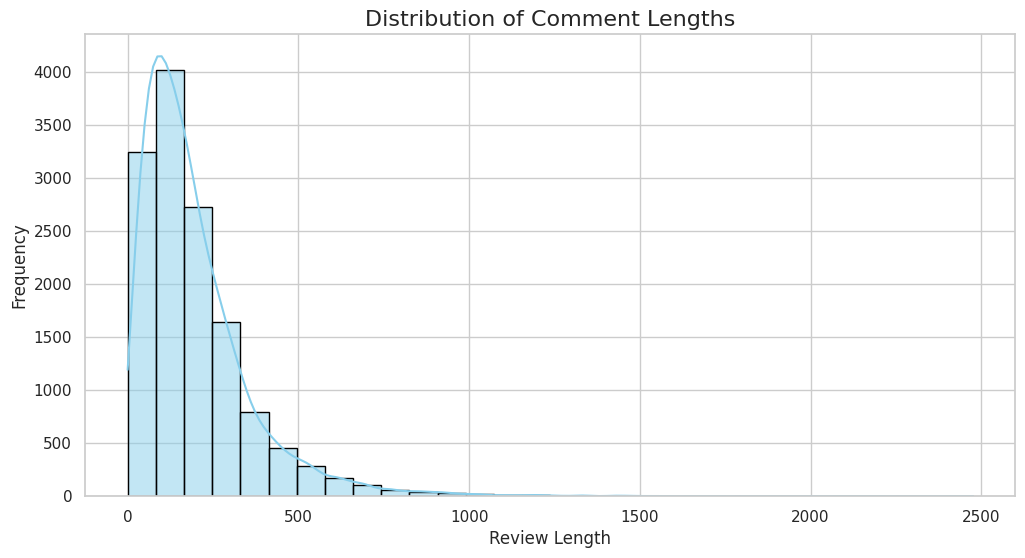

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")

plt.figure(figsize=(12, 6))

sns.histplot(df_train['Review_length'], bins=30, kde=True, color='skyblue', edgecolor='black')

plt.title('Distribution of Comment Lengths', fontsize=16)
plt.xlabel('Review Length', fontsize=12)
plt.ylabel('Frequency', fontsize=12)

plt.show()


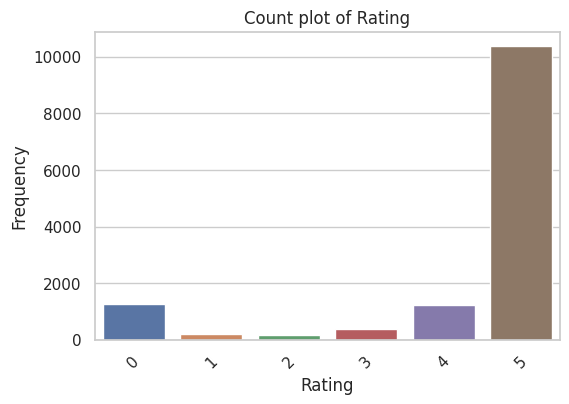

In [25]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6,4))
sns.countplot(x='Rating', data=df_train)
plt.xlabel('Rating')
plt.ylabel('Frequency')
plt.title('Count plot of Rating')
plt.xticks(rotation=45)
plt.show()

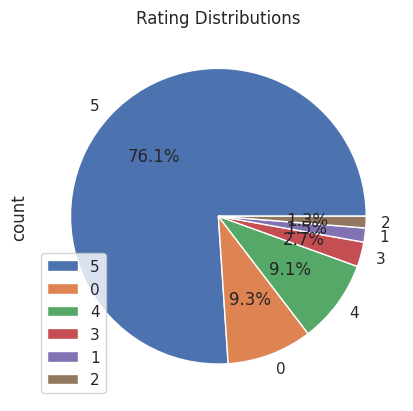

In [26]:
df_train['Rating'].value_counts().plot(kind='pie',autopct="%.1f%%")
plt.title("Rating Distributions")
plt.legend()
plt.show()

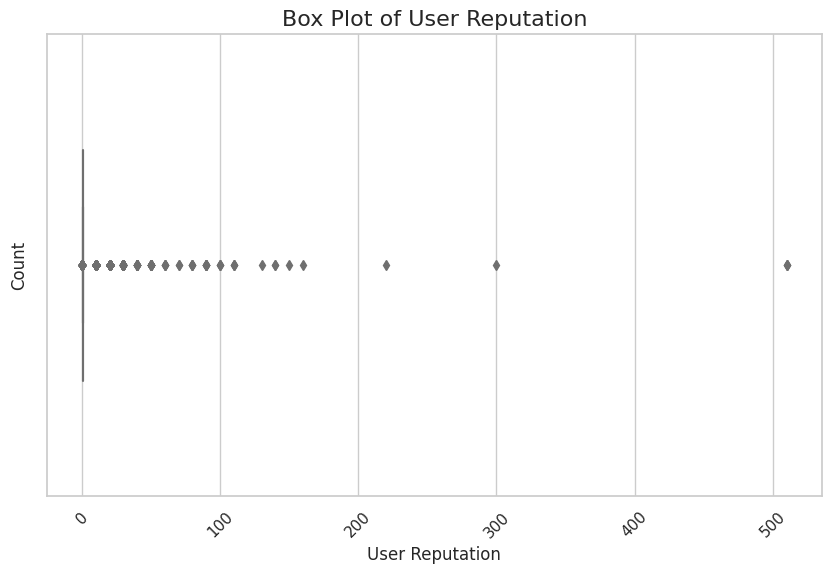

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")

plt.figure(figsize=(10, 6))

sns.boxplot(x='UserReputation', data=df_train, color='skyblue', width=0.5, fliersize=5)

plt.title('Box Plot of User Reputation', fontsize=16)
plt.xlabel('User Reputation', fontsize=12)
plt.ylabel('Count', fontsize=12)

plt.xticks(rotation=45)

plt.show()


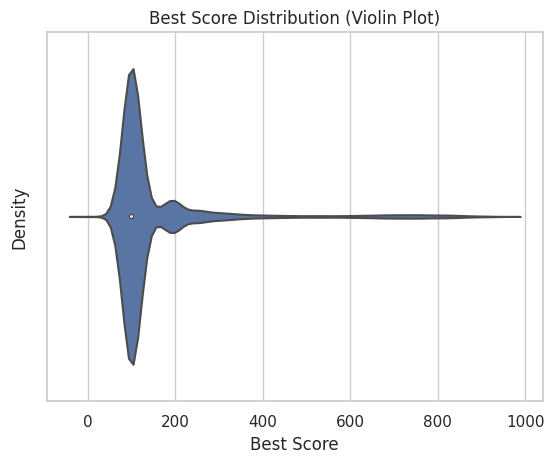

In [28]:
data = df_train
sns.violinplot(x='BestScore', data=data)
plt.title('Best Score Distribution (Violin Plot)')
plt.xlabel('Best Score')
plt.ylabel('Density')
plt.show()

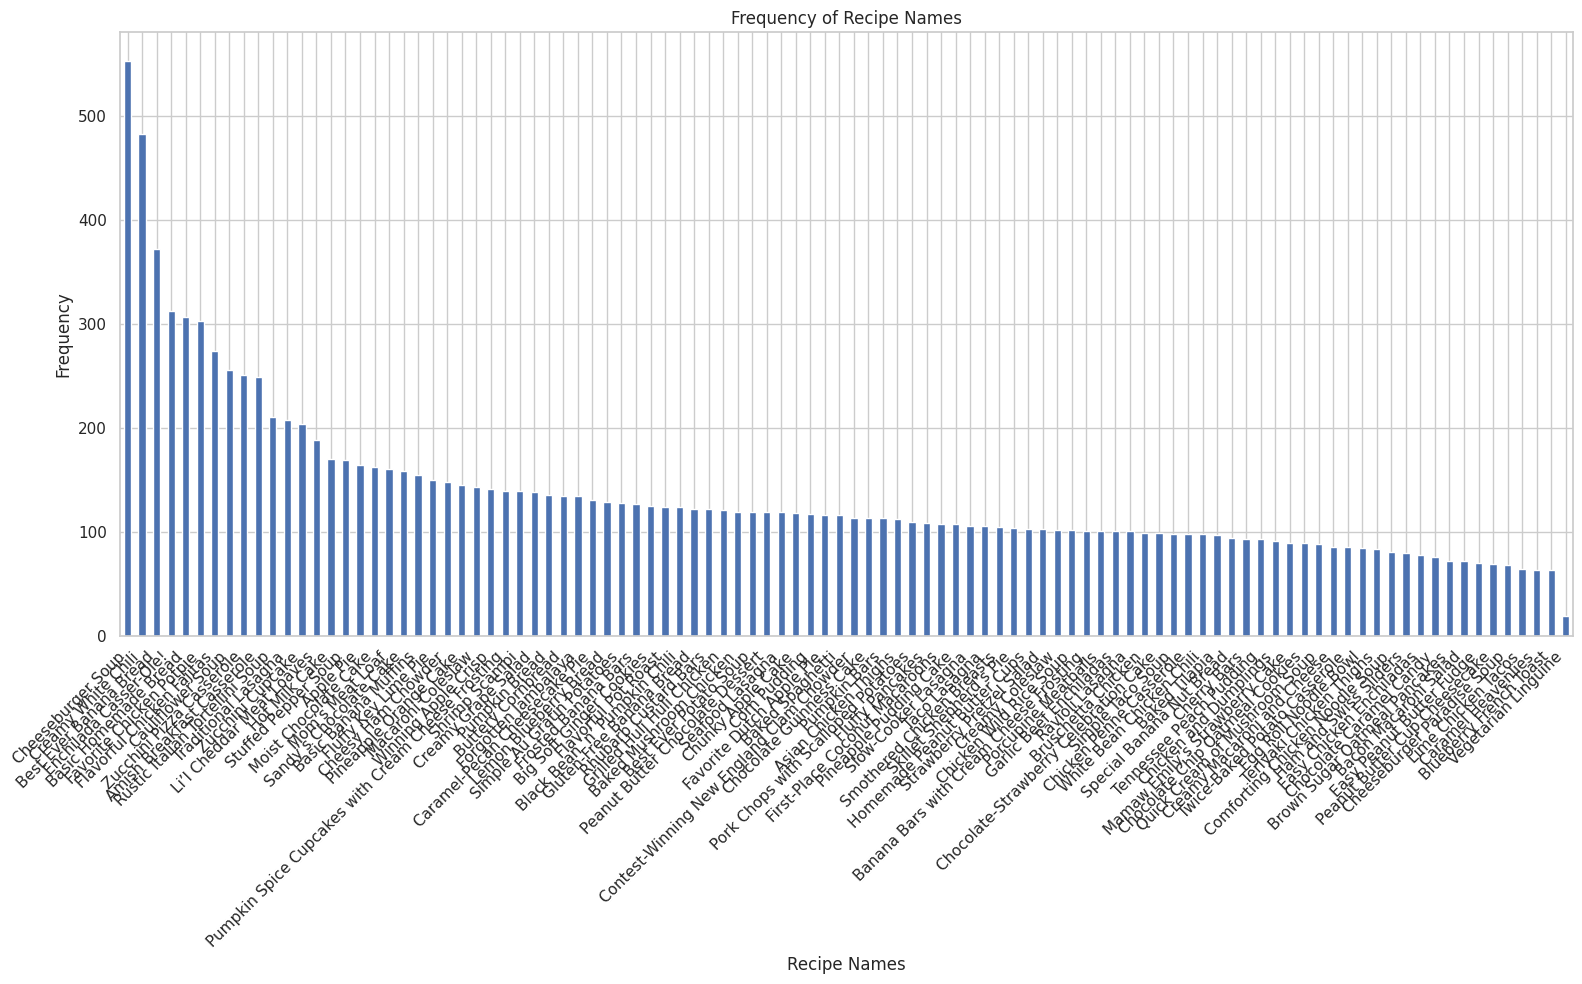

In [29]:
import matplotlib.pyplot as plt

# Assuming df_train contains a column "Recipe_Name"
recipe_names = df_train["RecipeName"]

# Count the occurrences of each recipe name
recipe_name_counts = recipe_names.value_counts()

# Plot a bar chart
plt.figure(figsize=(16, 10))
recipe_name_counts.plot(kind='bar')
plt.title('Frequency of Recipe Names')
plt.xlabel('Recipe Names')
plt.ylabel('Frequency')
plt.xticks(rotation=45, ha='right')  # Adjust rotation for better visibility
plt.tight_layout()
plt.show()


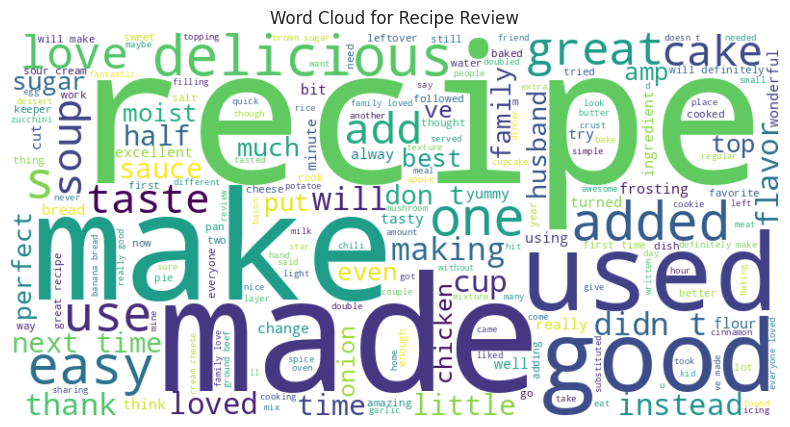

In [30]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from wordcloud import WordCloud

data = df_train

data['Recipe_Review'] = data['Recipe_Review'].astype(str)

wordcloud = WordCloud(width=800, height=400, background_color='white').generate(' '.join(data['Recipe_Review']))
plt.figure(figsize=(10,5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.title('Word Cloud for Recipe Review')
plt.axis('off')
plt.show()

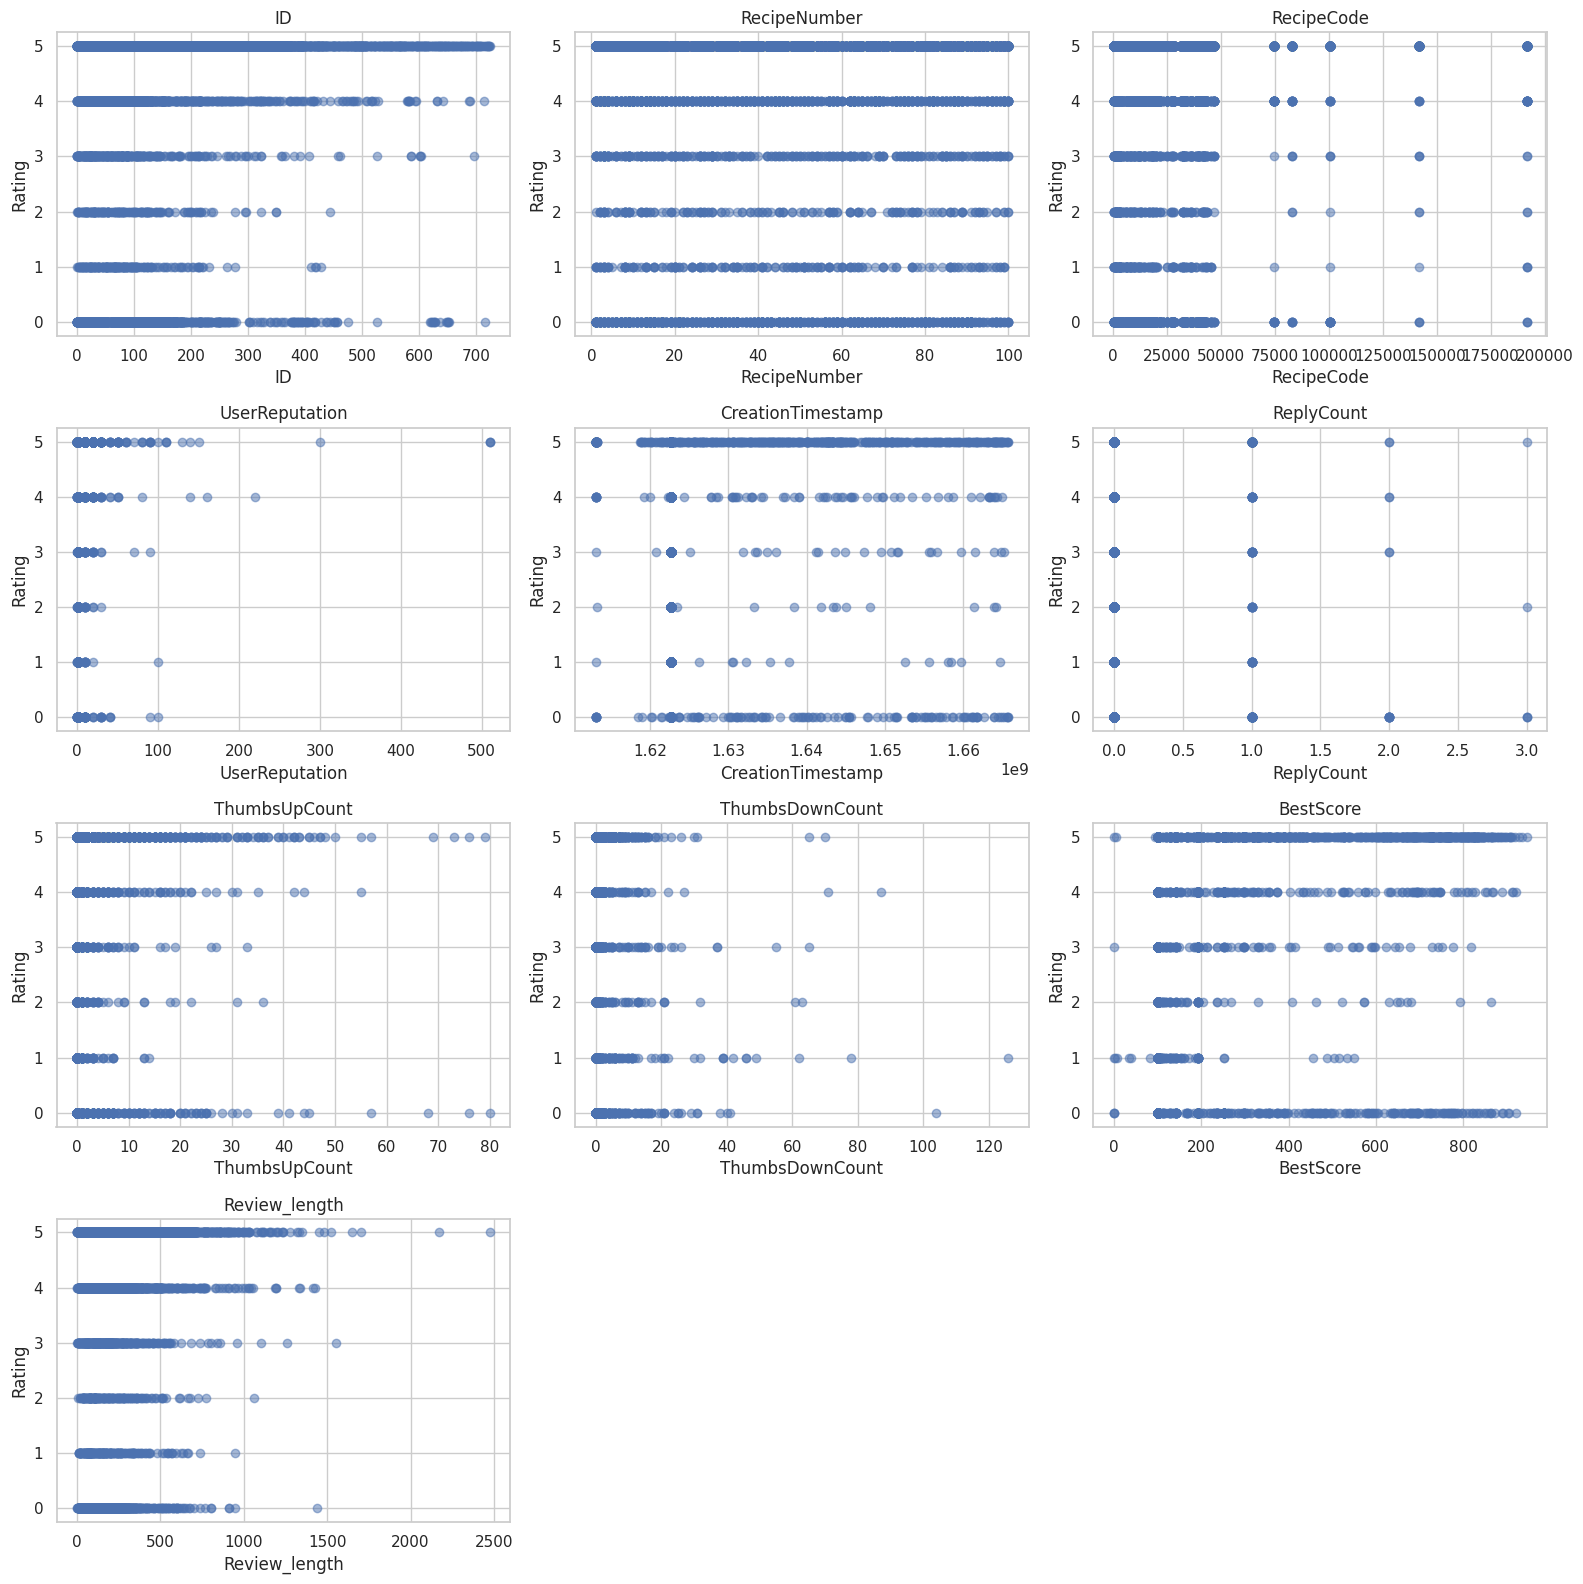

In [31]:
f_classification_data = df_train.drop(columns=['RecipeName', 'CommentID', 'UserID', 'UserName', 'Recipe_Review', 'Rating'])

# Calculate the number of subplots needed
num_features = len(f_classification_data.columns)
num_rows = (num_features - 1) // 3 + 1  # Calculate the number of rows needed

# Create subplots for scatter plots
fig, axes = plt.subplots(num_rows, 3, figsize=(16, 4 * num_rows))

# Loop through the columns and create scatter plots
for i, column in enumerate(f_classification_data.columns):
    row, col = divmod(i, 3)
    ax = axes[row, col]
    ax.scatter(f_classification_data[column], df_train['Rating'], alpha=0.5)
    ax.set_title(column)
    ax.set_xlabel(column)
    ax.set_ylabel("Rating")

# Remove any empty subplots
for i in range(num_features, num_rows * 3):
    fig.delaxes(axes.flatten()[i])

plt.tight_layout()
plt.show()


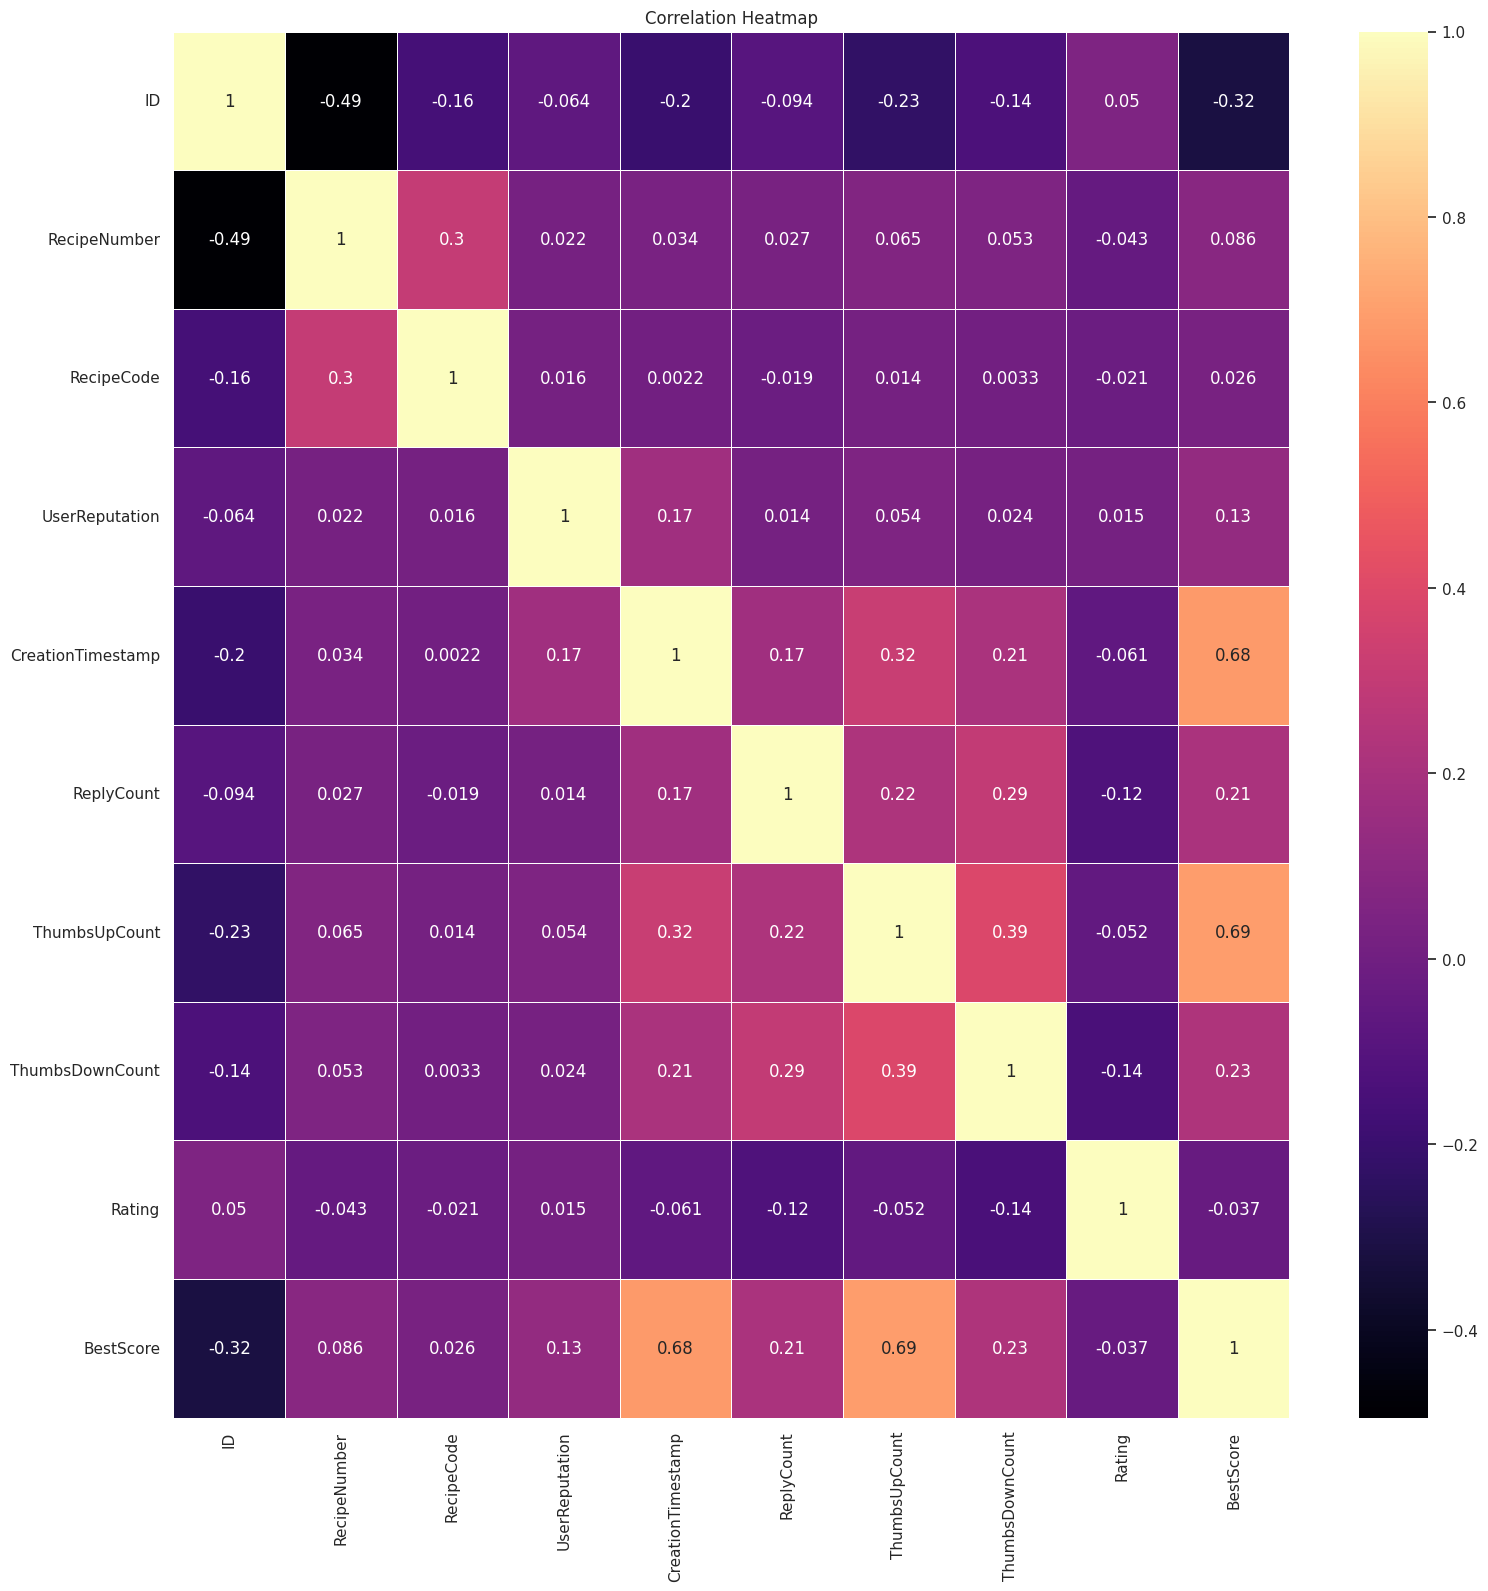

In [32]:
train2 = df_train1.select_dtypes(include=['int64', 'float64'])

correlation_matrix = train2.corr()

plt.figure(figsize=(18, 18))

sns.heatmap(correlation_matrix, annot=True, cmap='magma', linewidths=.5)
plt.title('Correlation Heatmap')
plt.show()

In [33]:
df_train.columns

Index(['ID', 'RecipeNumber', 'RecipeCode', 'RecipeName', 'CommentID', 'UserID',
       'UserName', 'UserReputation', 'CreationTimestamp', 'ReplyCount',
       'ThumbsUpCount', 'ThumbsDownCount', 'Rating', 'BestScore',
       'Recipe_Review', 'Review_length'],
      dtype='object')

In [34]:
X = df_train.drop(columns='Rating', axis=1)
X

,ID,RecipeNumber,RecipeCode,RecipeName,CommentID,UserID,UserName,UserReputation,CreationTimestamp,ReplyCount,ThumbsUpCount,ThumbsDownCount,BestScore,Recipe_Review,Review_length
0,70,71,12259,Banana Bars with Cream Cheese Frosting,sp_aUSaElGf_12259_c_149978,u_1oKVaBmiEKwAFyiHrDLoWpbel0J,misscoffeepot,20,1622717078,0,0,0,100,great recipe i have made them just as written ...,251
1,72,88,8202,Simple Taco Soup,sp_aUSaElGf_8202_c_310332,u_1oKZeRIXYzGNhGW8OMR3O4lX1ih,MichelleMalone,1,1622717852,0,0,1,100,this is an easy and quick recipe that is great...,399
2,458,3,2832,Cheeseburger Soup,sp_aUSaElGf_2832_c_206522,u_1oKYHUtdaD48KJCDYq5wfpAUxWz,jeannem32,1,1622717357,0,0,0,100,i think i was looking for something extra spec...,146
3,7,50,100276,Grilled Huli Huli Chicken,sp_aUSaElGf_100276_c_434088,u_1oKZCQcKQZdQhDVBS7oISc216VA,ds422,1,1622648899,0,0,0,100,this is our favorite grilled chicken recipe gr...,56
4,60,12,19731,Cauliflower Soup,sp_aUSaElGf_19731_c_387011,u_1oKd4sudZQPgu6YALiC7bW7mKMs,SusanHoward,1,1622718260,0,0,0,100,great basic recipe i added 2 teaspoons tuscan ...,127
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13631,115,98,11767,Quick Cream of Mushroom Soup,sp_aUSaElGf_11767_c_127710,u_1oKVbHjirkAIWwTjbt9dWyqENo2,elbay,1,1622716969,0,0,0,100,delicious very easy to make one minor change i...,150
13632,372,6,21444,Favorite Chicken Potpie,sp_aUSaElGf_21444_c_196030,u_1oKXoBnyJ2ocquNYwAhs19LMSrA,PauletteInhofe,1,1622717329,0,0,0,100,i made this pie for my family and they loved i...,286
13633,87,37,20170,Taco Lasagna,sp_aUSaElGf_20170_c_359338,u_1oKbGr5o9tj0mQl1rkVqzWnE481,Barbaralarkin,1,1622718089,0,0,0,100,very tasty,10
13634,48,63,24886,Chicken and Dumplings,sp_aUSaElGf_24886_c_175514,u_1oKWD7Dqjmc0oYHdW8Vm3fzhxJW,SammyPrissy,1,1622717192,0,0,0,100,i have made this numerous times it 39 s so goo...,56


In [35]:
df_train

,ID,RecipeNumber,RecipeCode,RecipeName,CommentID,UserID,UserName,UserReputation,CreationTimestamp,ReplyCount,ThumbsUpCount,ThumbsDownCount,Rating,BestScore,Recipe_Review,Review_length
0,70,71,12259,Banana Bars with Cream Cheese Frosting,sp_aUSaElGf_12259_c_149978,u_1oKVaBmiEKwAFyiHrDLoWpbel0J,misscoffeepot,20,1622717078,0,0,0,5,100,great recipe i have made them just as written ...,251
1,72,88,8202,Simple Taco Soup,sp_aUSaElGf_8202_c_310332,u_1oKZeRIXYzGNhGW8OMR3O4lX1ih,MichelleMalone,1,1622717852,0,0,1,5,100,this is an easy and quick recipe that is great...,399
2,458,3,2832,Cheeseburger Soup,sp_aUSaElGf_2832_c_206522,u_1oKYHUtdaD48KJCDYq5wfpAUxWz,jeannem32,1,1622717357,0,0,0,3,100,i think i was looking for something extra spec...,146
3,7,50,100276,Grilled Huli Huli Chicken,sp_aUSaElGf_100276_c_434088,u_1oKZCQcKQZdQhDVBS7oISc216VA,ds422,1,1622648899,0,0,0,5,100,this is our favorite grilled chicken recipe gr...,56
4,60,12,19731,Cauliflower Soup,sp_aUSaElGf_19731_c_387011,u_1oKd4sudZQPgu6YALiC7bW7mKMs,SusanHoward,1,1622718260,0,0,0,4,100,great basic recipe i added 2 teaspoons tuscan ...,127
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13631,115,98,11767,Quick Cream of Mushroom Soup,sp_aUSaElGf_11767_c_127710,u_1oKVbHjirkAIWwTjbt9dWyqENo2,elbay,1,1622716969,0,0,0,5,100,delicious very easy to make one minor change i...,150
13632,372,6,21444,Favorite Chicken Potpie,sp_aUSaElGf_21444_c_196030,u_1oKXoBnyJ2ocquNYwAhs19LMSrA,PauletteInhofe,1,1622717329,0,0,0,5,100,i made this pie for my family and they loved i...,286
13633,87,37,20170,Taco Lasagna,sp_aUSaElGf_20170_c_359338,u_1oKbGr5o9tj0mQl1rkVqzWnE481,Barbaralarkin,1,1622718089,0,0,0,5,100,very tasty,10
13634,48,63,24886,Chicken and Dumplings,sp_aUSaElGf_24886_c_175514,u_1oKWD7Dqjmc0oYHdW8Vm3fzhxJW,SammyPrissy,1,1622717192,0,0,0,5,100,i have made this numerous times it 39 s so goo...,56


In [36]:
y = df_train['Rating']
y

0        5
1        5
2        3
3        5
4        4
        ..
13631    5
13632    5
13633    5
13634    5
13635    5
Name: Rating, Length: 13636, dtype: int64

In [37]:
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size = 0.2,random_state = 42, stratify = y)
X_test = df_test
print('Training Data\t', X_train.shape, y_train.shape)
print('Validation Data\t', X_val.shape, y_val.shape)
print('Testing Data\t', X_test.shape)

Training Data	 (10908, 15) (10908,)
Validation Data	 (2728, 15) (2728,)
Testing Data	 (4546, 14)


In [38]:
metrics = pd.DataFrame(columns = ['Accuracy', 'F1_Score'])

In [39]:
class ModelPipeline:
    def __init__(self, classifier, count_params=None):
        self.numerical_feats = ['ReplyCount', 'ThumbsUpCount' ,'ThumbsDownCount']
        self.categorical_feats = ['RecipeCode']
        self.textual_feats = ['Recipe_Review']
        self.classifier = classifier
        self.count_params = count_params
        
        self.numerical_transformer = Pipeline(steps=[
            ('poly', PolynomialFeatures(degree=2, include_bias=False)),
            ('log', FunctionTransformer(np.log1p)),
            ('scaler', RobustScaler())
        ])

        self.categorical_transformer = Pipeline(steps=[
            ('ohe', OneHotEncoder())
        ])

        self.textual_transformer = Pipeline(steps=[
            ('count', CountVectorizer(**(count_params or {})))
        ])

        self.column_preprocessor = ColumnTransformer(
            transformers=[
                ('Numerical_Features', self.numerical_transformer, self.numerical_feats),
                ('Textual_Features', self.textual_transformer, self.textual_feats[0]),
                ('Categorical_Features', self.categorical_transformer, self.categorical_feats)
            ]
        )

        self.model = Pipeline(steps = [
            ('Column_Preprocessor', self.column_preprocessor),
            ('Feature_Selector',VarianceThreshold(threshold=0)),
            ('Classification_Model', self.classifier)
        ])
        
    def get_params(self, deep=True):
        return {"classifier": self.classifier, "count_params": self.count_params}
    
    def set_params(self, **parameters):
        for parameter, value in parameters.items():
            setattr(self, parameter, value)
        return self
    
    def fit_transform(self, X, y=None):
        return self.model.fit_transform(X, y)
    
    def predict(self, X, y=None):
        return self.model.predict(X)
    
    def predict_proba(self, X, y=None):
        return self.model.predict_proba(X)

    def transform(self, X):
        return self.model.transform(X)

    def fit(self, X, y=None):
        self.model.fit(X, y)
        return self

In [40]:
def cross_validation(model, X_train, y_train, X_test, y_test):
    cv = RepeatedStratifiedKFold(n_splits=2, n_repeats = 5, random_state=42)
    print('='*80 + '\n' + '-'*31 + ' Cross-Validation ' + '-'*31 + '\n' + '='*80)
    cv_scores = cross_val_score(model, X_train, y_train, scoring='accuracy', cv=cv, verbose = 3)
    print('\n[CV] Accuracy Score : {:.3f}%'.format(np.mean(cv_scores)*100))
    print('[CV] Std. Deviation : {:.3f}'.format(np.mean(cv_scores)))
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    print("\nClassification Report on Validation Data:")
    print(classification_report(y_test, y_pred))
    print('Overall Accuracy on Validation Data : {:.3f}%'.format(accuracy_score(y_test, y_pred)*100))

In [41]:
from sklearn import linear_model
from sklearn.metrics import accuracy_score, f1_score, classification_report

baseline_LR = ModelPipeline(classifier = linear_model.LogisticRegression())

baseline_LR.fit(X_train, y_train)
base_LR_pred = baseline_LR.predict(X_val)
metrics.loc['Baseline LR'] = [accuracy_score(y_val, base_LR_pred), f1_score(y_val, base_LR_pred, average = 'macro')]
print("\nAccuracy (Validation Data) : {}%".format(round(metrics.loc[metrics.index[-1]].Accuracy*100, 3)))
print("Macro F1-Score (Validation Data) : {}".format(round(metrics.loc[metrics.index[-1]].F1_Score, 3)))



Accuracy (Validation Data) : 76.173%
Macro F1-Score (Validation Data) : 0.351


In [42]:
LR_count_params = {'ngram_range': (1,4),'max_df': 0.35,'min_df': 1}
LR_model_params = {'random_state': 42, 'multi_class': 'multinomial', 'solver': 'saga', 'penalty': 'l2','C': 4.4,'fit_intercept': True,'max_iter': 1000,'n_jobs': -1}
hpt_LR = ModelPipeline(classifier = linear_model.LogisticRegression(**LR_model_params), count_params = LR_count_params)
hpt_LR.model

Pipeline(steps=[('Column_Preprocessor',
                 ColumnTransformer(transformers=[('Numerical_Features',
                                                  Pipeline(steps=[('poly',
                                                                   PolynomialFeatures(include_bias=False)),
                                                                  ('log',
                                                                   FunctionTransformer(func=<ufunc 'log1p'>)),
                                                                  ('scaler',
                                                                   RobustScaler())]),
                                                  ['ReplyCount',
                                                   'ThumbsUpCount',
                                                   'ThumbsDownCount']),
                                                 ('Textual_Features',
                                                  Pipeline(steps=[('count',
                                                                   CountVectorizer(max_df=0.35,
                                                                                   ngram_range=(1,
                                                                                                4)))]),
                                                  'Recipe_Review'),
                                                 ('Categorical_Features',
                                                  Pipeline(steps=[('ohe',
                                                                   OneHotEncoder())]),
                                                  ['RecipeCode'])])),
                ('Feature_Selector', VarianceThreshold(threshold=0)),
                ('Classification_Model',
                 LogisticRegression(C=4.4, max_iter=1000,
                                    multi_class='multinomial', n_jobs=-1,
                                    random_state=42, solver='saga'))])

In [43]:
# Fit the classifier on the training data
hpt_LR.fit(X_train, y_train)
hpt_LR_pred = hpt_LR.predict(X_val)
metrics.loc['HPT LR'] = [accuracy_score(y_val, hpt_LR_pred), f1_score(y_val, hpt_LR_pred, average = 'macro')]
print("\nAccuracy (Validation Data) : {}%".format(round(metrics.loc[metrics.index[-1]].Accuracy*100, 3)))
print("Macro F1-Score (Validation Data) : {}".format(round(metrics.loc[metrics.index[-1]].F1_Score, 3)))


Accuracy (Validation Data) : 78.446%
Macro F1-Score (Validation Data) : 0.342


In [44]:
baseline_XGB = ModelPipeline(classifier = xgb.XGBClassifier())

baseline_XGB.fit(X_train, y_train)
base_XGB_pred = baseline_XGB.predict(X_val)
metrics.loc['Baseline XGB'] = [accuracy_score(y_val, base_XGB_pred), f1_score(y_val, base_XGB_pred, average = 'macro')]
print("\nAccuracy (Validation Data) : {}%".format(round(metrics.loc[metrics.index[-1]].Accuracy*100, 3)))
print("Macro F1-Score (Validation Data) : {}".format(round(metrics.loc[metrics.index[-1]].F1_Score, 3)))


Accuracy (Validation Data) : 78.482%
Macro F1-Score (Validation Data) : 0.357


In [45]:
XGB_count_params = {'ngram_range': (1,4),'max_df': 0.75,'min_df': 18}
XGB_model_params = {'random_state': 42,'n_estimators': 1000,'max_depth': 8,'learning_rate': 0.06,'subsample': 0.6, 'colsample_bytree': 0.6,'n_jobs': -1}
hpt_XGB = ModelPipeline(classifier = xgb.XGBClassifier(**XGB_model_params), count_params = XGB_count_params)
hpt_XGB.model

Pipeline(steps=[('Column_Preprocessor',
                 ColumnTransformer(transformers=[('Numerical_Features',
                                                  Pipeline(steps=[('poly',
                                                                   PolynomialFeatures(include_bias=False)),
                                                                  ('log',
                                                                   FunctionTransformer(func=<ufunc 'log1p'>)),
                                                                  ('scaler',
                                                                   RobustScaler())]),
                                                  ['ReplyCount',
                                                   'ThumbsUpCount',
                                                   'ThumbsDownCount']),
                                                 ('Textual_Features',
                                                  Pipeline(steps=[('count',
                                                                   CountVectorizer(max_d...
                               feature_types=None, gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.06,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=8, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=1000, n_jobs=-1,
                               num_parallel_tree=None, random_state=42, ...))])

In [46]:
hpt_XGB.fit(X_train, y_train)
hpt_XGB_pred = hpt_XGB.predict(X_val)
metrics.loc['HPT XGB'] = [accuracy_score(y_val, hpt_XGB_pred), f1_score(y_val, hpt_XGB_pred, average = 'macro')]
print("\nAccuracy (Validation Data) : {}%".format(round(metrics.loc[metrics.index[-1]].Accuracy*100, 3)))
print("Macro F1-Score (Validation Data) : {}".format(round(metrics.loc[metrics.index[-1]].F1_Score, 3)))


Accuracy (Validation Data) : 78.739%
Macro F1-Score (Validation Data) : 0.345


In [47]:
baseline_SVC = ModelPipeline(classifier = svm.SVC())

baseline_SVC.fit(X_train, y_train)
base_SVC_pred = baseline_SVC.predict(X_val)
metrics.loc['Baseline SVC'] = [accuracy_score(y_val, base_SVC_pred), f1_score(y_val, base_SVC_pred, average = 'macro')]
print("\nAccuracy (Validation Data) : {}%".format(round(metrics.loc[metrics.index[-1]].Accuracy*100, 3)))
print("Macro F1-Score (Validation Data) : {}".format(round(metrics.loc[metrics.index[-1]].F1_Score, 3)))


Accuracy (Validation Data) : 76.32%
Macro F1-Score (Validation Data) : 0.174


In [48]:
SVC_count_params = {'ngram_range': (1,4),'max_df': 0.35,'min_df': 9}
SVC_model_params = {'random_state': 42, 'kernel': 'poly', 'probability': True,'C': 0.05,'decision_function_shape': 'ovo','max_iter': 250}
hpt_SVC = ModelPipeline(classifier = svm.SVC(**SVC_model_params), count_params = SVC_count_params)
hpt_SVC.model

Pipeline(steps=[('Column_Preprocessor',
                 ColumnTransformer(transformers=[('Numerical_Features',
                                                  Pipeline(steps=[('poly',
                                                                   PolynomialFeatures(include_bias=False)),
                                                                  ('log',
                                                                   FunctionTransformer(func=<ufunc 'log1p'>)),
                                                                  ('scaler',
                                                                   RobustScaler())]),
                                                  ['ReplyCount',
                                                   'ThumbsUpCount',
                                                   'ThumbsDownCount']),
                                                 ('Textual_Features',
                                                  Pipeline(steps=[('count',
                                                                   CountVectorizer(max_df=0.35,
                                                                                   min_df=9,
                                                                                   ngram_range=(1,
                                                                                                4)))]),
                                                  'Recipe_Review'),
                                                 ('Categorical_Features',
                                                  Pipeline(steps=[('ohe',
                                                                   OneHotEncoder())]),
                                                  ['RecipeCode'])])),
                ('Feature_Selector', VarianceThreshold(threshold=0)),
                ('Classification_Model',
                 SVC(C=0.05, decision_function_shape='ovo', kernel='poly',
                     max_iter=250, probability=True, random_state=42))])

In [49]:
# Creating Ensemble of the Top-2 Performing Models
# Fitting the models on whole training data
hpt_LR.fit(X, y)
hpt_XGB.fit(X, y)

y_prob_pred_LR = hpt_LR.predict_proba(X_test)
y_prob_pred_XGB = hpt_XGB.predict_proba(X_test)

In [50]:
# Combining the Predicted Probabililties of each class from the classifiers and averaging them to get proba in desired range
y_proba_pred_ensemble= (y_prob_pred_LR + y_prob_pred_XGB)/2

In [51]:
# Getting weighted probabilities as fix the imbalancing effect from the probabilities
y_proba_pred = y_proba_pred_ensemble * np.array([0.631, 1.895, 1.907, 1.783, 0.36, 0.497])

In [52]:
# Predicting Class Label based on their weighted probability
y_pred = np.argmax(y_proba_pred, axis=1)

In [53]:
pred_df = pd.DataFrame()
pred_df['ID'] = [i + 1 for i in range(len(y_pred))]
pred_df['Rating'] = y_pred
pred_df.to_csv('submission.csv', index = False)

In [54]:
# from sklearn.linear_model import LogisticRegression
# from sklearn.metrics import accuracy_score

# log_model = LogisticRegression(random_state = 42, multi_class='multinomial', solver='saga', penalty='l2', C=25, tol=7e-4, fit_intercept= True, max_iter = 300, n_jobs =-1)
# log_model.fit(X_train_enc, y_train)
# y_pred = log_model.predict(X_test_enc)

# accuracy = accuracy_score(y_test, y_pred)
# print("Accuracy:", accuracy)

In [55]:
# from xgboost import XGBClassifier
# from sklearn.metrics import accuracy_score

# xgb_model = XGBClassifier(
# learning_rate = 0.1,
# n_estimators=170,
# max_depth=11,
# min_child_weight=1,
# n_jobs = -1)

# xgb_model.fit(X_train_enc, y_train)
# y_pred = xgb_model.predict(X_test_enc)

# accuracy = accuracy_score(y_test, y_pred)
# print("Accuracy:", accuracy)

In [56]:
# from sklearn.svm import LinearSVC
# from sklearn.metrics import accuracy_score

# svc_model = LinearSVC(penalty='l2', loss='squared_hinge', tol=0.1, C=1, fit_intercept=True, max_iter=1000, dual=True)
# svc_model.fit(X_train_enc, y_train)
# y_pred = svc_model.predict(X_test_enc)

# accuracy = accuracy_score(y_test, y_pred)
# print("Accuracy:", accuracy)

In [57]:
# accuracy = accuracy_score(y_test, y_pred_class_test)
# print("Accuracy:", accuracy)

In [58]:
# test_enc.shape

In [59]:
# y_pred_class

In [60]:
# y_pred = y_pred_class
# submission = pd.DataFrame(columns = ["ID","Rating"])
# submission["ID"] = [i for i in range(1,len(y_pred)+1)]
# submission["Rating"] = y_pred
# submission.to_csv('submission.csv',index=False)

In [61]:
# from sklearn.linear_model import LogisticRegression
# from sklearn.metrics import accuracy_score

# log_model = LogisticRegression(C=25, max_iter=1000, solver='saga', penalty='l2')
# log_model.fit(X_train_enc, y_train)
# y_pred = log_model.predict(X_test_enc)

# accuracy = accuracy_score(y_test, y_pred)
# print("Accuracy:", accuracy)

In [62]:
# from sklearn.svm import LinearSVC
# from sklearn.metrics import accuracy_score

# svc_model = LinearSVC(penalty='l2', loss='squared_hinge', tol=0.01, C=1, fit_intercept=True, max_iter=1000, dual=True, verbose= False)
# svc_model.fit(X_train_enc, y_train)
# y_pred = svc_model.predict(X_test_enc)

# accuracy = accuracy_score(y_test, y_pred)
# print("Accuracy:", accuracy)

In [63]:
# pred_df = pd.DataFrame()
# pred_df['ID'] = [i + 1 for i in range(len(y_pred))]
# pred_df['Rating'] = y_pred
# pred_df.to_csv('submission.csv', index = False)

In [64]:
# pd.read_csv("submission.csv")

In [65]:
# df_test['Recipe_Review'] = df_test['Recipe_Review'].fillna('')

In [66]:
# df_test = df_test['Recipe_Review']

In [67]:
# df_test_review = vectorizer.transform(df_test)

In [68]:
# y_pred = svc_model.predict(df_test_review)
# submission = pd.DataFrame(columns = ["ID","Rating"])
# submission["ID"] = [i for i in range(1,len(y_pred)+1)]
# submission["Rating"] = y_pred
# submission.to_csv('submission.csv',index=False)

In [69]:
pd.read_csv("submission.csv")

,ID,Rating
0,1,5
1,2,5
2,3,5
3,4,1
4,5,5
...,...,...
4541,4542,5
4542,4543,5
4543,4544,5
4544,4545,1
